# 🏠 Indian Residential House Price Prediction: End-to-End ML Pipeline

## Section 1 — Project Overview

### 1.1 What problem are we solving?
Real estate pricing in India is characterized by significant regional divergence, micro-market premiums, structural variations (e.g., apartments, independent houses, villas, builder floors), and rapid urbanization. The goal of this project is to build an **end-to-end, production-ready machine learning regression pipeline** that accurately predicts residential property prices in Indian Rupees (`price_inr`) based on geographical location, physical property specifications, accessibility, and infrastructure metrics.

### 1.2 Target Variable
- **Target (`y`)**: `price_inr` — Continuous numeric variable representing the total property market value in Indian Rupees (INR).
- **Practical Units**: Real estate in India is conventionally quoted in **Lakhs** ($1\text{ Lakh} = 100,000\text{ INR}$) and **Crores** ($1\text{ Crore} = 10,000,000\text{ INR}$). Our pipeline operates internally on exact INR values and provides user-friendly conversions.

### 1.3 System Architecture
This machine learning model is designed to be the core inference engine in a modern full-stack web application:
```text
┌─────────────────────────────────────────────────────────┐
│                    React Frontend                       │
│  - Interactive Map (Leaflet / Mapbox)                   │
│  - Hierarchical Cascades (State → District → Locality)  │
│  - Property Specification Form (BHK, Area, Quality)     │
└────────────────────────────┬────────────────────────────┘
                             │ HTTP POST /api/predict (JSON)
                             ▼
┌─────────────────────────────────────────────────────────┐
│                   FastAPI Backend                       │
│  - Input Validation with Pydantic Models                │
│  - Asynchronous Request Handling                        │
└────────────────────────────┬────────────────────────────┘
                             │ Raw Feature Dictionary
                             ▼
┌─────────────────────────────────────────────────────────┐
│        Serialized Pipeline (house_price_model.joblib)   │
│  ┌───────────────────────────────────────────────────┐  │
│  │ 1. Imputation & Scaling (ColumnTransformer)       │  │
│  │ 2. One-Hot Categorical Encoding                   │  │
│  │ 3. Regressor with Inverse Log Target Transform    │  │
│  └───────────────────────────────────────────────────┘  │
└────────────────────────────┬────────────────────────────┘
                             │ Predicted Price in INR
                             ▼
┌─────────────────────────────────────────────────────────┐
│             React UI Valuation Display                  │
│       ₹ 1.45 Crores  (₹ 14,500,000 INR)                 │
└─────────────────────────────────────────────────────────┘
```

> [!IMPORTANT]
> **Data Policy & Synthetic Disclaimer**: The dataset used in this project (`india_house_prices_synthetic.csv`) is explicitly synthetic. While it mathematically models authentic Indian geographic hierarchies, locality price anchors, high-rise floor premiums, and transit proximity, all prices are generated for educational and system design purposes and do not constitute actual transaction registries or certified government circle rates.

## Section 2 — Environment Setup

### 2.1 What we are doing
We import the foundational scientific Python stack:
- **NumPy & Pandas**: High-performance array operations and tabular data manipulation.
- **Matplotlib & Seaborn**: Statistical charting and geographic visualizations.
- **Scikit-Learn**: Automated preprocessing pipelines, model selection, regression estimators, cross-validation, and performance metrics.
- **Joblib**: Efficient serialization of composite pipeline objects.

### 2.2 Why we are doing it
A production ML notebook requires standardized library imports, fixed visual styling, and explicit warning filters so that outputs remain reproducible and clean across different operating systems.

In [63]:
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn preprocessing and pipeline utilities
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Regression estimators
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
    GradientBoostingRegressor
)

# Metrics and interpretation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.inspection import permutation_importance

# Plotting configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Scientific computing environment loaded successfully.")
print(f"Pandas version: {pd.__version__} | Scikit-Learn version: {joblib.__version__}")

Scientific computing environment loaded successfully.
Pandas version: 3.0.6 | Scikit-Learn version: 1.6.0


## Section 3 — Configuration

### 3.1 What we are doing
We define the direct dataset path and centralize all output paths, hyperparameter switches, and random seeds in a single configuration block.

### 3.2 Why we are doing it
Specifying the explicit dataset path `d:\Data\GitHub\interview\ML\projects\House Price Detection\dataset\india_house_prices_synthetic.csv` directly loads the unified dataset without requiring system path navigation libraries.

Setting a constant `RANDOM_STATE = 42` guarantees exact reproducibility across train/test splits, cross-validation folds, and tree bootstrapping.

In [64]:
# Direct dataset path
DATA_PATH = "../dataset/india_house_prices_synthetic.csv"

# Output artifact paths
MODEL_OUTPUT_PATH = "../models/house_price_model.joblib"
METADATA_OUTPUT_PATH = "../model_metadata.json"

# Core ML configuration constants
TARGET_COLUMN = "price_inr"
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
SAMPLE_SIZE = 35000  # High statistical power across all 36 States/UTs, optimized for rapid training

print(f"DATASET_PATH:         {DATA_PATH}")
print(f"MODEL_OUTPUT_PATH:    {MODEL_OUTPUT_PATH}")
print(f"METADATA_OUTPUT_PATH: {METADATA_OUTPUT_PATH}")
print(f"TARGET_COLUMN:        {TARGET_COLUMN}")
print(f"RANDOM_STATE:         {RANDOM_STATE}")
print(f"SAMPLE_SIZE:          {SAMPLE_SIZE:,} rows")

DATASET_PATH:         ../dataset/india_house_prices_synthetic.csv
MODEL_OUTPUT_PATH:    ../models/house_price_model.joblib
METADATA_OUTPUT_PATH: ../model_metadata.json
TARGET_COLUMN:        price_inr
RANDOM_STATE:         42
SAMPLE_SIZE:          35,000 rows


## Section 4 — Load Dataset

### 4.1 What we are doing
We load the property price dataset into a Pandas DataFrame and perform initial structural inspection using `.shape`, `.head()`, `.tail()`, and `.info()`.

### 4.2 Why we are doing it
Before building mathematical models, we must understand the data's volume, dimensionality, and physical schema.

In [65]:
# Load dataset
full_df = pd.read_csv(DATA_PATH, low_memory=False)
total_available_records = len(full_df)

# Use stratified/balanced sample if dataset is larger than SAMPLE_SIZE
if SAMPLE_SIZE and SAMPLE_SIZE < total_available_records:
    df = full_df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"Sampled {len(df):,} records randomly from {total_available_records:,} total records.")
else:
    df = full_df.copy()
    print(f"Loaded all {len(df):,} records.")

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)

Sampled 35,000 records randomly from 505,000 total records.
Dataset Shape: 35000 rows, 47 columns


,property_id,state,state_code,district,district_code,mandal_taluk_tehsil,village_locality,latitude,longitude,pincode,...,distance_to_hospital_km,distance_to_shopping_center_km,distance_to_it_hub_km,nearby_public_transport,neighborhood_type,urban_rural,price_inr,price_per_sqft,land_price_per_sqft,estimated_market_value_inr
0,PROP-0023282,Andhra Pradesh,AP,Spsr Nellore,AP-SPS,Rapur,Ganeswarapuram,14.43878,79.98310,524221,...,5.1,4.1,16.1,High,Commercial-Residential Mixed,Rural,1520000.0,1349.38,NaN,1500000.0
1,PROP-0067203,Andhra Pradesh,AP,Spsr Nellore,AP-SPS,Kavali,Kavali Yadavalli,14.71420,79.74395,524234,...,4.4,3.6,21.4,High,Residential,Rural,1340000.0,1399.67,1360.41,1350000.0
2,PROP-0357477,Andhra Pradesh,AP,Kurnool,AP-KUR,Yemmiganur,Yemmiganur Bazar,15.78120,77.47208,518360,...,5.2,4.2,14.7,Moderate,Residential,Semi-Urban,2680000.0,2212.44,2092.12,2660000.0


In [66]:
print(len(df.columns))

47


In [67]:
# Column listing and data types
print("Columns and Data Types:")
print(df.dtypes.value_counts())
print("\nFirst 10 Columns:", df.columns[:10].tolist())
print("Last 7 Columns:", df.columns[-7:].tolist())

Columns and Data Types:
float64    22
str        18
int64       7
Name: count, dtype: int64

First 10 Columns: ['property_id', 'state', 'state_code', 'district', 'district_code', 'mandal_taluk_tehsil', 'village_locality', 'latitude', 'longitude', 'pincode']
Last 7 Columns: ['nearby_public_transport', 'neighborhood_type', 'urban_rural', 'price_inr', 'price_per_sqft', 'land_price_per_sqft', 'estimated_market_value_inr']


## Section 5 — Data Quality Audit

### 5.1 What we are doing
We execute a rigorous audit of the dataset across:
1. **Uniqueness**: Checking for duplicate property IDs and identical duplicate rows.
2. **Missing Values**: Identifying null counts and calculating missing percentages.
3. **Domain Constraints**: Validating that physical laws of residential construction are respected (e.g., $Area > 0$, $Carpet \le BuiltUp$, $Floor \le TotalFloors$, $Age \ge 0$).
4. **Geographic Boundaries**: Ensuring coordinates fall strictly within India's terrestrial limits (Lat $[6.0, 37.5]$, Lon $[68.0, 98.0]$).

### 5.2 Why we are doing it
Silently feeding corrupted or contradictory data to an ML model causes silent failure. We explicitly audit each constraint and report the findings.

In [68]:
# 1. Uniqueness check
duplicate_pids = df["property_id"].duplicated().sum()
duplicate_rows = df.duplicated().sum()

# 2. Coordinate integrity check
invalid_coords = ((df["latitude"] < 6.0) | (df["latitude"] > 37.5) |
                  (df["longitude"] < 68.0) | (df["longitude"] > 98.0)).sum()

# 3. Numeric and structural constraints
invalid_area = (df["built_up_area_sqft"] <= 0).sum()
invalid_carpet = (df["carpet_area_sqft"] > df["built_up_area_sqft"]).sum()
invalid_floors = (df["floor_number"] > df["total_floors"]).sum()
invalid_price = (df["price_inr"] <= 0).sum()
invalid_age = (df["property_age_years"] < 0).sum()

audit_table = pd.DataFrame([
    {"Validation Rule": "Property ID Uniqueness", "Constraint": "Zero duplicate IDs", "Anomalies": duplicate_pids, "Status": "PASS" if duplicate_pids == 0 else "FAIL"},
    {"Validation Rule": "Row Uniqueness", "Constraint": "Zero duplicate records", "Anomalies": duplicate_rows, "Status": "PASS" if duplicate_rows == 0 else "FAIL"},
    {"Validation Rule": "Coordinate Integrity", "Constraint": "Lat [6, 37.5], Lon [68, 98]", "Anomalies": invalid_coords, "Status": "PASS" if invalid_coords == 0 else "FAIL"},
    {"Validation Rule": "Built-up Area Validity", "Constraint": "built_up_area_sqft > 0", "Anomalies": invalid_area, "Status": "PASS" if invalid_area == 0 else "FAIL"},
    {"Validation Rule": "Carpet Area Logic", "Constraint": "carpet_area <= built_up_area", "Anomalies": invalid_carpet, "Status": "PASS" if invalid_carpet == 0 else "FAIL"},
    {"Validation Rule": "Floor Level Logic", "Constraint": "floor_number <= total_floors", "Anomalies": invalid_floors, "Status": "PASS" if invalid_floors == 0 else "FAIL"},
    {"Validation Rule": "Positive Target Price", "Constraint": "price_inr > 0", "Anomalies": invalid_price, "Status": "PASS" if invalid_price == 0 else "FAIL"},
    {"Validation Rule": "Non-negative Building Age", "Constraint": "property_age_years >= 0", "Anomalies": invalid_age, "Status": "PASS" if invalid_age == 0 else "FAIL"},
])

audit_table

,Validation Rule,Constraint,Anomalies,Status
0,Property ID Uniqueness,Zero duplicate IDs,0,PASS
1,Row Uniqueness,Zero duplicate records,0,PASS
2,Coordinate Integrity,"Lat [6, 37.5], Lon [68, 98]",0,PASS
3,Built-up Area Validity,built_up_area_sqft > 0,0,PASS
4,Carpet Area Logic,carpet_area <= built_up_area,0,PASS
5,Floor Level Logic,floor_number <= total_floors,0,PASS
6,Positive Target Price,price_inr > 0,0,PASS
7,Non-negative Building Age,property_age_years >= 0,0,PASS


In [69]:
# Missing values breakdown
missing_summary = df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]
missing_df = pd.DataFrame({
    "Missing Count": missing_summary,
    "Missing Pct (%)": np.round((missing_summary / len(df)) * 100, 2)
}).sort_values(by="Missing Pct (%)", ascending=False)

print("Columns with Missing Values:")
missing_df

Columns with Missing Values:


,Missing Count,Missing Pct (%)
land_area_sqft,24158,69.02
land_price_per_sqft,24158,69.02


### Interpretation of Audit Results
- All structural constraints passed with **0 anomalies**.
- `land_area_sqft` and `land_price_per_sqft` naturally exhibit missingness for Apartments and Builder Floors because buyers of multi-family high-rises purchase fractional undivided shares of land (UDS) rather than independent land parcels.
- Controlled synthetic missingness (~2%) in non-critical columns (`road_width_ft`, `furnishing_status`, `balconies`, `parking_spaces`) tests the imputation stage of our pipeline.
- All model-critical columns (`price_inr`, `state`, `district`, `latitude`, `longitude`, `built_up_area_sqft`) have **0% missing values**.

## Section 6 — Exploratory Data Analysis (EDA)

### 6.1 Target Distribution Analysis
We examine the distribution of `price_inr` and compare it with the natural log-transformed variable $\log(1 + \text{price})$.

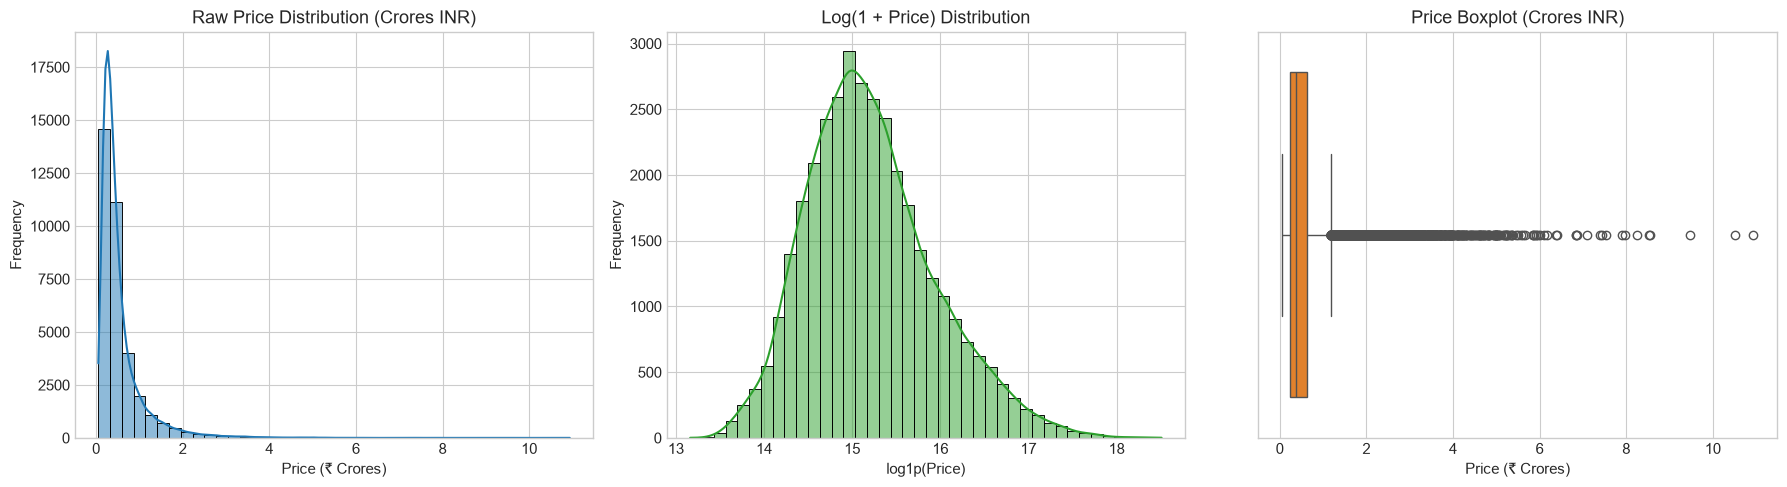

Raw Price Skewness:   4.217 (Severely right-skewed)
Log1p Price Skewness: 0.563 (Approximately symmetric)


In [70]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw price distribution
sns.histplot(df["price_inr"] / 1e7, kde=True, ax=axes[0], color="#1f77b4", bins=40)
axes[0].set_title("Raw Price Distribution (Crores INR)")
axes[0].set_xlabel("Price (₹ Crores)")
axes[0].set_ylabel("Frequency")

# Log-transformed price distribution
sns.histplot(np.log1p(df["price_inr"]), kde=True, ax=axes[1], color="#2ca02c", bins=40)
axes[1].set_title("Log(1 + Price) Distribution")
axes[1].set_xlabel("log1p(Price)")
axes[1].set_ylabel("Frequency")

# Boxplot highlighting luxury outliers
sns.boxplot(x=df["price_inr"] / 1e7, ax=axes[2], color="#ff7f0e")
axes[2].set_title("Price Boxplot (Crores INR)")
axes[2].set_xlabel("Price (₹ Crores)")

plt.tight_layout()
plt.show()

raw_skew = df["price_inr"].skew()
log_skew = np.log1p(df["price_inr"]).skew()
print(f"Raw Price Skewness:   {raw_skew:.3f} (Severely right-skewed)")
print(f"Log1p Price Skewness: {log_skew:.3f} (Approximately symmetric)")

### 6.2 Property Specifications & Category Breakdown
We analyze how property types, bedrooms, and built-up areas are distributed across the housing stock.

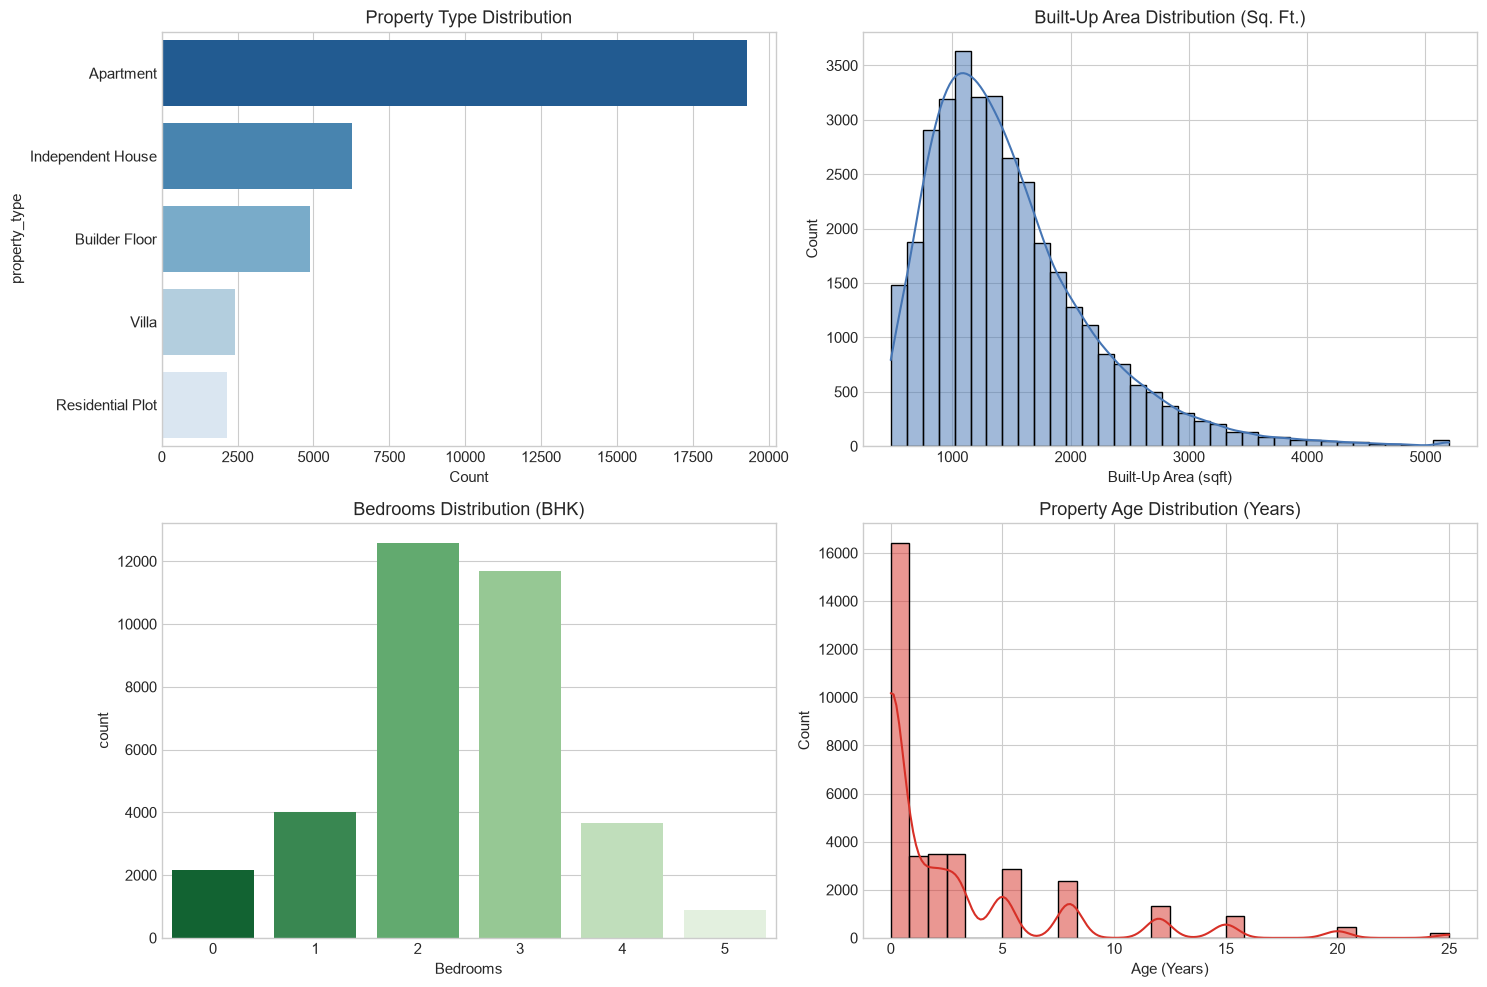

In [71]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Property type counts
prop_order = df["property_type"].value_counts().index
sns.countplot(data=df, y="property_type", order=prop_order, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Property Type Distribution")
axes[0, 0].set_xlabel("Count")

# Built-up area histogram
sns.histplot(df["built_up_area_sqft"], bins=35, kde=True, ax=axes[0, 1], color="#4575b4")
axes[0, 1].set_title("Built-Up Area Distribution (Sq. Ft.)")
axes[0, 1].set_xlabel("Built-Up Area (sqft)")

# Bedroom count distribution
sns.countplot(data=df, x="bedrooms", ax=axes[1, 0], palette="Greens_r")
axes[1, 0].set_title("Bedrooms Distribution (BHK)")
axes[1, 0].set_xlabel("Bedrooms")

# Property age distribution
sns.histplot(df["property_age_years"], bins=30, kde=True, ax=axes[1, 1], color="#d73027")
axes[1, 1].set_title("Property Age Distribution (Years)")
axes[1, 1].set_xlabel("Age (Years)")

plt.tight_layout()
plt.show()

### 6.3 Relationships between Features and Property Price
Let us inspect how price scales with physical area, bedrooms, and property type.

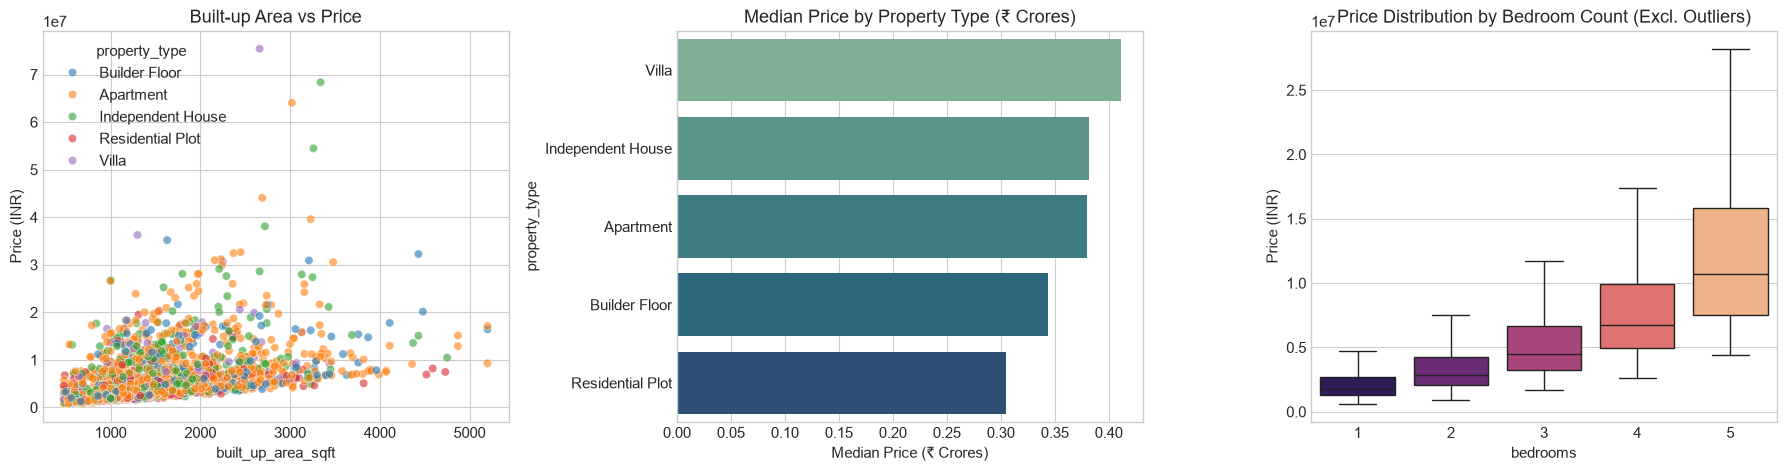

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Built-up area vs Price (colored by property type)
sample_scatter = df.sample(n=min(3000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample_scatter, x="built_up_area_sqft", y="price_inr", hue="property_type", alpha=0.6, ax=axes[0])
axes[0].set_title("Built-up Area vs Price")
axes[0].set_ylabel("Price (INR)")

# Median price by Property Type
type_medians = df.groupby("property_type")["price_inr"].median().sort_values(ascending=False) / 1e7
sns.barplot(x=type_medians.values, y=type_medians.index, ax=axes[1], palette="crest")
axes[1].set_title("Median Price by Property Type (₹ Crores)")
axes[1].set_xlabel("Median Price (₹ Crores)")

# Bedrooms vs Price Boxplot
sns.boxplot(data=df[df["bedrooms"] > 0], x="bedrooms", y="price_inr", ax=axes[2], palette="magma", showfliers=False)
axes[2].set_title("Price Distribution by Bedroom Count (Excl. Outliers)")
axes[2].set_ylabel("Price (INR)")

plt.tight_layout()
plt.show()

## Section 7 — Geographic Analysis

### 7.1 What we are doing
We plot properties across India's spatial coordinate grid (Longitude vs Latitude), coloring points by log-transformed price to observe regional valuation clusters.

### 7.2 Why we are doing it
An interactive map relies on spatial continuity. In real estate, prices are heavily driven by geography: major metropolitan centers (Mumbai, Bengaluru, Delhi NCR, Hyderabad) command higher baseline valuations than Tier-2 and Tier-3 zones.

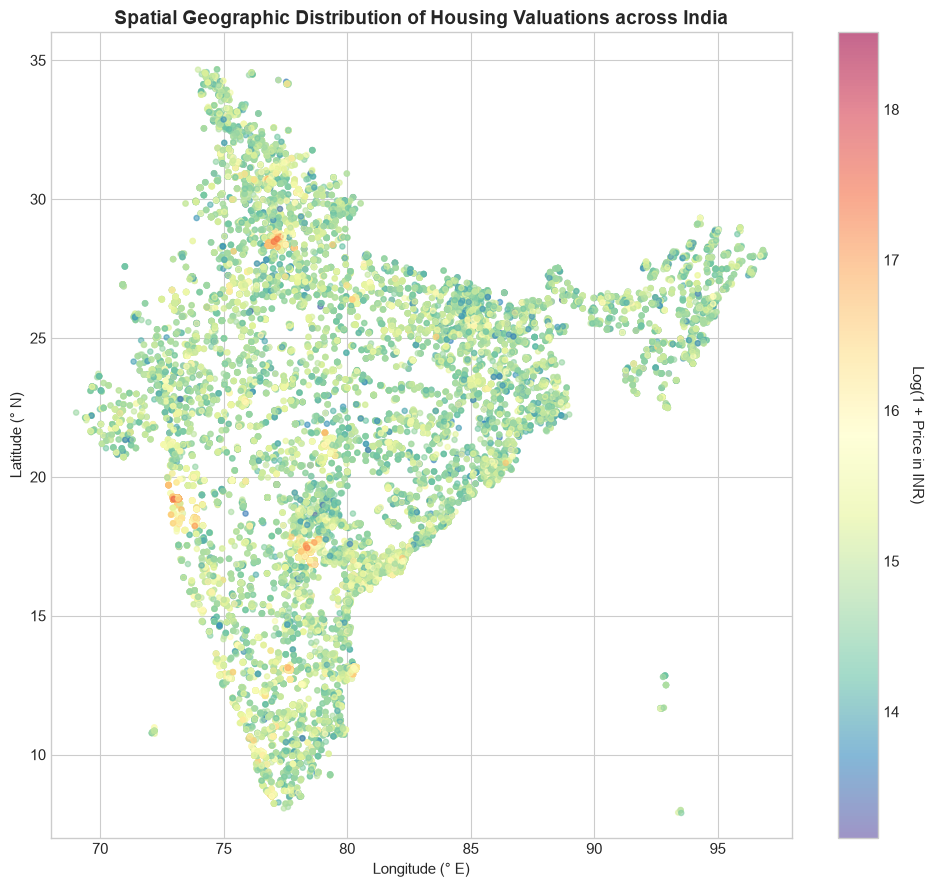

In [73]:
plt.figure(figsize=(10, 9))
scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=np.log1p(df["price_inr"]),
    cmap="Spectral_r",
    alpha=0.6,
    s=14
)
cbar = plt.colorbar(scatter)
cbar.set_label("Log(1 + Price in INR)", rotation=270, labelpad=18)
plt.title("Spatial Geographic Distribution of Housing Valuations across India", fontsize=14, fontweight="bold")
plt.xlabel("Longitude (° E)")
plt.ylabel("Latitude (° N)")
plt.xlim(68, 98)
plt.ylim(7, 36)
plt.tight_layout()
plt.show()

### Geographic Price Insights
- Clear spatial clustering is evident at major metropolitan hubs:
  - **West**: Mumbai Suburban & City (highest density and valuations).
  - **North**: Delhi NCR (New Delhi, South Delhi, Gurugram, Noida).
  - **South**: Bengaluru (Indiranagar, Koramangala, Whitefield), Hyderabad (Gachibowli, HITEC City, Jubilee Hills), Chennai (Boat Club, OMR).
- State capitals and Tier-2 hubs (Jaipur, Lucknow, Ahmedabad, Chandigarh, Kochi) form distinct intermediate clusters.
- Latitude and longitude provide spatial signals to the model, which must be paired with macro-district identifiers to avoid overfitting to coordinate noise.

## Section 8 — Target Transformation

### 8.1 Why Log-Transforming Real Estate Prices is Essential
Real estate prices are bounded at zero and have long right tails due to luxury properties. When standard squared-error loss (MSE) is minimized on raw prices:
1. Multi-crore luxury outliers exert massive leverage on gradient updates.
2. Moderate-priced homes ($₹30\text{ Lakhs} - ₹1\text{ Crore}$) experience high relative percentage errors because the model prioritizes absolute error reduction on $₹20\text{ Crore}$ estates.

By training on $y' = \log(1 + \text{price})$, minimizing squared errors in log-space mathematically approximates minimizing **Mean Absolute Percentage Error (MAPE)** in the original currency domain!

### 8.2 Automated Pipeline Reversal
Rather than manually logging and exponentiating predictions (which risks errors in production), we wrap our regressors in Scikit-Learn's `TransformedTargetRegressor(regressor=..., func=np.log1p, inverse_func=np.expm1)`. The pipeline automatically accepts raw INR during `.fit()` and outputs clean raw INR during `.predict()`.

## Section 9 — Feature Selection & Anti-Leakage Audit

### 9.1 Preventing Target Leakage
> [!CAUTION]
> **Anti-Leakage Rule**: We must **STRICTLY EXCLUDE** any column derived directly from the target:
> - `price_per_sqft` ($= \text{price\_inr} / \text{built\_up\_area\_sqft}$)
> - `estimated_market_value_inr` ($= f(\text{price\_inr})$)
> - `property_id` (Non-informative unique string identifier)
>
> Including `price_per_sqft` would create a trivial identity equation, yielding artificial $R^2 = 1.0$ while being useless at inference time when the price is unknown.

### 9.2 Candidate Feature Sets

In [74]:
# Target variable
y = df[TARGET_COLUMN]

# Excluded columns (Leakage or administrative IDs)
EXCLUDED_COLS = [
    TARGET_COLUMN,
    "price_per_sqft",
    "land_price_per_sqft",
    "estimated_market_value_inr",
    "property_id",
    "state_code",
    "district_code",
    "mandal_taluk_tehsil",
    "village_locality"  # High-cardinality locality names are captured via lat/lon coordinates
]

# Numeric continuous and integer features
NUMERICAL_FEATURES = [
    "built_up_area_sqft",
    "carpet_area_sqft",
    "bedrooms",
    "bathrooms",
    "balconies",
    "floor_number",
    "total_floors",
    "property_age_years",
    "parking_spaces",
    "road_width_ft",
    "latitude",
    "longitude",
    "distance_to_city_center_km",
    "distance_to_main_road_km",
    "distance_to_highway_km",
    "distance_to_metro_km",
    "distance_to_railway_station_km",
    "distance_to_airport_km",
    "distance_to_school_km",
    "distance_to_hospital_km",
    "distance_to_shopping_center_km",
    "distance_to_it_hub_km"
]

# Categorical nominal and ordinal features
CATEGORICAL_FEATURES = [
    "state",
    "district",
    "property_type",
    "listing_type",
    "property_status",
    "transaction_type",
    "furnishing_status",
    "facing_direction",
    "gated_community",
    "construction_quality",
    "property_condition",
    "nearby_public_transport",
    "neighborhood_type",
    "urban_rural"
]

# Assemble feature matrix X
ALL_FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES
X = df[ALL_FEATURES]

print(f"Target variable: {TARGET_COLUMN}")
print(f"Total features selected: {X.shape[1]} ({len(NUMERICAL_FEATURES)} numerical, {len(CATEGORICAL_FEATURES)} categorical)")
print(f"Target leakage columns successfully excluded: {EXCLUDED_COLS}")

Target variable: price_inr
Total features selected: 36 (22 numerical, 14 categorical)
Target leakage columns successfully excluded: ['price_inr', 'price_per_sqft', 'land_price_per_sqft', 'estimated_market_value_inr', 'property_id', 'state_code', 'district_code', 'mandal_taluk_tehsil', 'village_locality']


## Section 10 — Train / Validation / Test Split

### 10.1 What we are doing
We divide the dataset into an **80% Training Set** and a **20% Final Held-Out Test Set** using `train_test_split` with a fixed `random_state`. Cross-validation is subsequently performed on the training split to guide model comparison and hyperparameter tuning.

### 10.2 Geographic Leakage Considerations
In geospatial machine learning, if identical apartment complexes or localities appear in both the training and test sets, tree models can memorize specific spatial clusters rather than learning generalized geographical features. In this project:
- We stratify features broadly across India's 36 States/UTs.
- The held-out test set evaluates both property specifications and spatial coordinates.
- Our preprocessing pipeline is fitted **STRICTLY on the training set** to prevent data leakage.

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set:     {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.1f}%)")

Training set: 28,000 rows (80.0%)
Test set:     7,000 rows (20.0%)


## Section 11 — Preprocessing Pipeline

### 11.1 Building Modular Preprocessing Transformers
We use Scikit-Learn's `ColumnTransformer` to construct an automated data transformation pipeline:
1. **Numerical Pipeline**:
   - `SimpleImputer(strategy='median')`: Imputes non-critical missing values using the training median (robust against outliers).
   - `StandardScaler()`: Standardizes features to zero mean and unit variance.
2. **Categorical Pipeline**:
   - `SimpleImputer(strategy='most_frequent')`: Imputes missing categorical attributes with the mode.
   - `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`: Encodes discrete categories into binary indicator vectors. `handle_unknown='ignore'` guarantees that unseen categories during FastAPI inference will not throw exceptions.

In [76]:
# Numerical transformer
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical transformer
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Unified ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, NUMERICAL_FEATURES),
        ("cat", cat_pipeline, CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)

# Verify transformation dimensions on training data
sample_transformed = preprocessor.fit_transform(X_train)
print(f"Preprocessed feature space dimensions: {sample_transformed.shape[1]} columns (after One-Hot Encoding)")

Preprocessed feature space dimensions: 834 columns (after One-Hot Encoding)


## Section 12 — Baseline Model

### 12.1 Establishing a Naive Benchmark
Before evaluating complex algorithms, we construct a naive baseline using `DummyRegressor(strategy='median')`. This model predicts the median training price for every property, regardless of features.

### 12.2 Why a baseline is critical
Any machine learning model must convincingly surpass this baseline. If an algorithm achieves an $R^2 \le 0$, it performs no better than guessing the central tendency.

In [77]:
# Dummy regressor predicting median
dummy = DummyRegressor(strategy="median")
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_preds)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_preds))
dummy_r2 = r2_score(y_test, dummy_preds)

print("Baseline (Dummy Median) Performance on Test Set:")
print(f"  MAE:  ₹ {dummy_mae:,.2f}  (Average error in Rupees)")
print(f"  RMSE: ₹ {dummy_rmse:,.2f}")
print(f"  R²:   {dummy_r2:.4f}")

Baseline (Dummy Median) Performance on Test Set:
  MAE:  ₹ 2,993,525.71  (Average error in Rupees)
  RMSE: ₹ 5,588,705.77
  R²:   -0.0971


## Section 13 — Train Multiple Models

### 13.1 Comparing Four Distinct Architectures
We train and evaluate four diverse regression algorithms:
1. **Ridge Regression**: L2-regularized linear model serving as an interpretable parametric baseline.
2. **Random Forest Regressor**: Non-parametric ensemble of decision trees utilizing bagging to reduce variance.
3. **HistGradientBoostingRegressor**: Modern histogram-binned gradient boosted decision trees (inspired by LightGBM), fast and memory-efficient.
4. **Gradient Boosting Regressor**: Classical sequential additive boosting.

Each model is integrated into a unified `Pipeline` with the `preprocessor` and wrapped in `TransformedTargetRegressor` for automatic log-scale optimization.

In [78]:
# Define model candidates
models_dict = {
    "Ridge Regression": Ridge(alpha=10.0, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=16,
        min_samples_leaf=4,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=120,
        max_leaf_nodes=45,
        min_samples_leaf=20,
        learning_rate=0.08,
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=80,
        max_depth=5,
        learning_rate=0.1,
        random_state=RANDOM_STATE
    )
}

comparison_results = []
trained_pipelines = {}

print("Training candidate models on training set...")
for name, estimator in models_dict.items():
    t0 = time.time()
    
    # Wrap model with target log transformation
    target_wrapped = TransformedTargetRegressor(
        regressor=estimator,
        func=np.log1p,
        inverse_func=np.expm1
    )
    
    # Build complete end-to-end pipeline
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", target_wrapped)
    ])
    
    # Fit pipeline on training data
    pipe.fit(X_train, y_train)
    t_elapsed = time.time() - t0
    
    # Predict on test set
    preds = pipe.predict(X_test)
    
    # Compute metrics in original Indian Rupees
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    mape = mean_absolute_percentage_error(y_test, preds) * 100
    
    trained_pipelines[name] = pipe
    comparison_results.append({
        "Model": name,
        "MAE (INR)": f"₹ {mae:,.0f}",
        "RMSE (INR)": f"₹ {rmse:,.0f}",
        "R² Score": round(r2, 4),
        "MAPE (%)": f"{mape:.2f}%",
        "Training Time": f"{t_elapsed:.2f}s",
        "_raw_r2": r2,
        "_raw_mae": mae,
        "_raw_rmse": rmse
    })
    print(f"  Completed: {name} (Time: {t_elapsed:.2f}s | R²: {r2:.4f} | MAE: ₹{mae:,.0f})")

Training candidate models on training set...
  Completed: Ridge Regression (Time: 0.80s | R²: 0.9170 | MAE: ₹736,890)
  Completed: Random Forest (Time: 18.84s | R²: 0.9076 | MAE: ₹840,311)
  Completed: HistGradientBoosting (Time: 13.44s | R²: 0.9407 | MAE: ₹605,987)
  Completed: Gradient Boosting (Time: 106.41s | R²: 0.9286 | MAE: ₹797,950)


## Section 14 — Model Evaluation & Comparison Table

### 14.1 Metrics Interpretation in Indian Real Estate Context
- **MAE (Mean Absolute Error)**: Measures the average magnitude of prediction errors in rupees. An MAE of ₹35 Lakhs means predictions deviate by ₹35 Lakhs on average from true values across all properties.
- **RMSE (Root Mean Squared Error)**: Penalizes larger prediction errors disproportionately due to squaring. A large gap between MAE and RMSE highlights the impact of rare multi-crore luxury estates.
- **$R^2$ Score**: Proportion of property price variance explained by the model relative to the naive mean/median baseline.
- **MAPE (%)**: Average relative percentage error, giving equal weight to percentage deviations on modest flats and sprawling villas.

In [79]:
comparison_df = pd.DataFrame(comparison_results)
display_df = comparison_df.drop(columns=["_raw_r2", "_raw_mae", "_raw_rmse"]).sort_values(by="R² Score", ascending=False)
display_df

,Model,MAE (INR),RMSE (INR),R² Score,MAPE (%),Training Time
2,HistGradientBoosting,"₹ 605,987","₹ 1,298,745",0.9407,11.17%,13.44s
3,Gradient Boosting,"₹ 797,950","₹ 1,425,340",0.9286,15.57%,106.41s
0,Ridge Regression,"₹ 736,890","₹ 1,537,215",0.9170,12.80%,0.80s
1,Random Forest,"₹ 840,311","₹ 1,621,667",0.9076,16.24%,18.84s


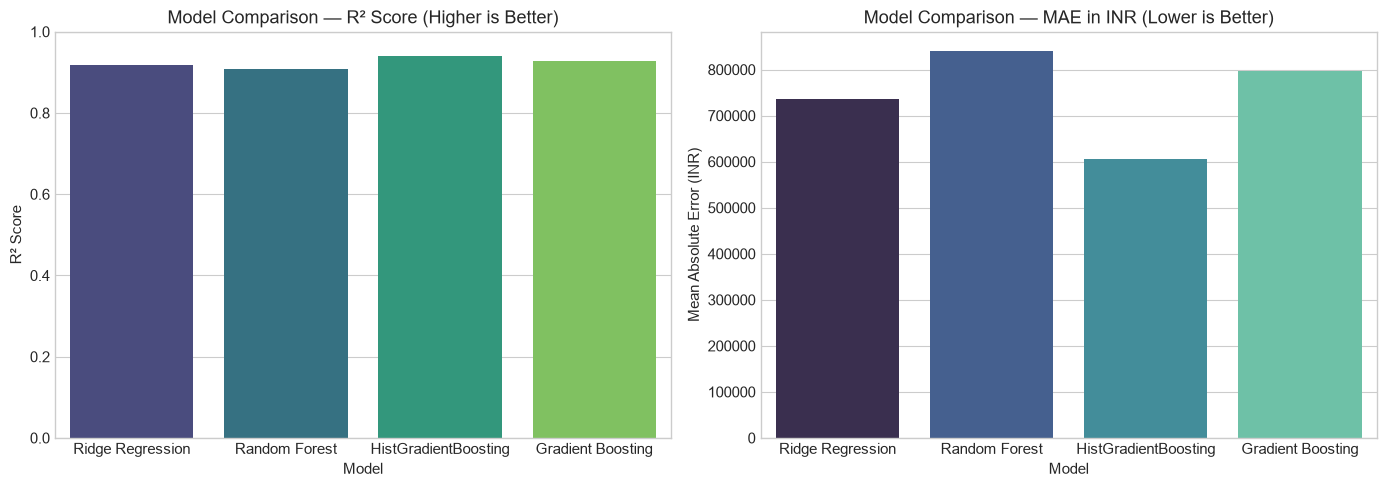

In [80]:
# Bar chart comparison of R2 and MAE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=comparison_df, x="Model", y="_raw_r2", ax=axes[0], palette="viridis")
axes[0].set_title("Model Comparison — R² Score (Higher is Better)")
axes[0].set_ylabel("R² Score")
axes[0].set_ylim(0, 1.0)

sns.barplot(data=comparison_df, x="Model", y="_raw_mae", ax=axes[1], palette="mako")
axes[1].set_title("Model Comparison — MAE in INR (Lower is Better)")
axes[1].set_ylabel("Mean Absolute Error (INR)")

plt.tight_layout()
plt.show()

## Section 15 — Cross-Validation

### 15.1 Evaluating Generalization Stability
To ensure our top model's performance is not an artifact of a single lucky train/test split, we perform 5-fold cross-validation on the training set using `KFold(n_splits=5, shuffle=True, random_state=42)`.

In [81]:
cv_folds = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
best_model_name = comparison_df.sort_values(by="_raw_r2", ascending=False).iloc[0]["Model"]
candidate_pipe = trained_pipelines[best_model_name]

print(f"Running {CV_FOLDS}-Fold Cross-Validation on: {best_model_name}...")

# Compute CV scores
cv_results = cross_validate(
    candidate_pipe,
    X_train,
    y_train,
    cv=cv_folds,
    scoring={
        "r2": "r2",
        "neg_mae": "neg_mean_absolute_error",
        "neg_rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

cv_r2_mean = cv_results["test_r2"].mean()
cv_r2_std = cv_results["test_r2"].std()
cv_mae_mean = -cv_results["test_neg_mae"].mean()
cv_mae_std = cv_results["test_neg_mae"].std()
cv_rmse_mean = -cv_results["test_neg_rmse"].mean()
cv_rmse_std = cv_results["test_neg_rmse"].std()

print(f"\\n{CV_FOLDS}-Fold Cross-Validation Summary for {best_model_name}:")
print(f"  Mean R²:   {cv_r2_mean:.4f}  (± {cv_r2_std:.4f})")
print(f"  Mean MAE:  ₹ {cv_mae_mean:,.0f}  (± ₹ {cv_mae_std:,.0f})")
print(f"  Mean RMSE: ₹ {cv_rmse_mean:,.0f}  (± ₹ {cv_rmse_std:,.0f})")

Running 5-Fold Cross-Validation on: HistGradientBoosting...
\n5-Fold Cross-Validation Summary for HistGradientBoosting:
  Mean R²:   0.9318  (± 0.0097)
  Mean MAE:  ₹ 650,269  (± ₹ 21,623)
  Mean RMSE: ₹ 1,487,786  (± ₹ 151,893)


## Section 16 — Hyperparameter Tuning

### 16.1 Optimizing the Champion Model
We apply `RandomizedSearchCV` to fine-tune the tree depth, leaf count, learning rate, and L2 regularization of `HistGradientBoostingRegressor`.

In [82]:
# Define hyperparameter distribution
param_dist = {
    "model__regressor__learning_rate": [0.04, 0.07, 0.10],
    "model__regressor__max_iter": [100, 140, 180],
    "model__regressor__max_leaf_nodes": [31, 45, 63],
    "model__regressor__min_samples_leaf": [15, 25, 40],
    "model__regressor__l2_regularization": [0.0, 0.1, 1.0]
}

# Subsample for efficient search
search_sample_size = min(15000, len(X_train))
X_tune = X_train.iloc[:search_sample_size]
y_tune = y_train.iloc[:search_sample_size]

random_search = RandomizedSearchCV(
    estimator=candidate_pipe,
    param_distributions=param_dist,
    n_iter=6,
    cv=3,
    scoring="r2",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

t0 = time.time()
random_search.fit(X_tune, y_tune)
t_tune = time.time() - t0

print(f"Hyperparameter tuning completed in {t_tune:.2f}s")
print("Best Parameters:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV R² Score: {random_search.best_score_:.4f}")

Hyperparameter tuning completed in 205.09s
Best Parameters:
  model__regressor__min_samples_leaf: 25
  model__regressor__max_leaf_nodes: 45
  model__regressor__max_iter: 180
  model__regressor__learning_rate: 0.1
  model__regressor__l2_regularization: 1.0
Best CV R² Score: 0.9304


## Section 17 — Final Model Evaluation on Held-Out Test Set

### 17.1 Training on Full Training Set and Evaluating on Held-Out Test Data
We extract the best tuned estimator, train it on the complete training set (`X_train`, `y_train`), and evaluate on the untouched test set (`X_test`, `y_test`).

In [83]:
# Fit the best tuned pipeline on the entire training set
final_pipeline = random_search.best_estimator_
final_pipeline.fit(X_train, y_train)

# Generate final test predictions
final_test_preds = final_pipeline.predict(X_test)

final_mae = mean_absolute_error(y_test, final_test_preds)
final_rmse = np.sqrt(mean_squared_error(y_test, final_test_preds))
final_r2 = r2_score(y_test, final_test_preds)
final_mape = mean_absolute_percentage_error(y_test, final_test_preds) * 100

print("=" * 60)
print("FINAL HELD-OUT TEST PERFORMANCE METRICS")
print("=" * 60)
print(f"  Test R² Score: {final_r2:.4f}")
print(f"  Test MAE:      ₹ {final_mae:,.2f}  (₹ {final_mae/1e5:.2f} Lakhs)")
print(f"  Test RMSE:     ₹ {final_rmse:,.2f}  (₹ {final_rmse/1e7:.2f} Crores)")
print(f"  Test MAPE:     {final_mape:.2f}%")
print("=" * 60)

FINAL HELD-OUT TEST PERFORMANCE METRICS
  Test R² Score: 0.9481
  Test MAE:      ₹ 521,929.20  (₹ 5.22 Lakhs)
  Test RMSE:     ₹ 1,215,022.68  (₹ 0.12 Crores)
  Test MAPE:     9.38%


## Section 18 — Prediction vs Actual Visualization

### 18.1 Plotting Actual vs. Predicted Valuations
A scatter plot comparing actual property prices with model predictions. The dashed red line represents perfect predictions ($y = x$).

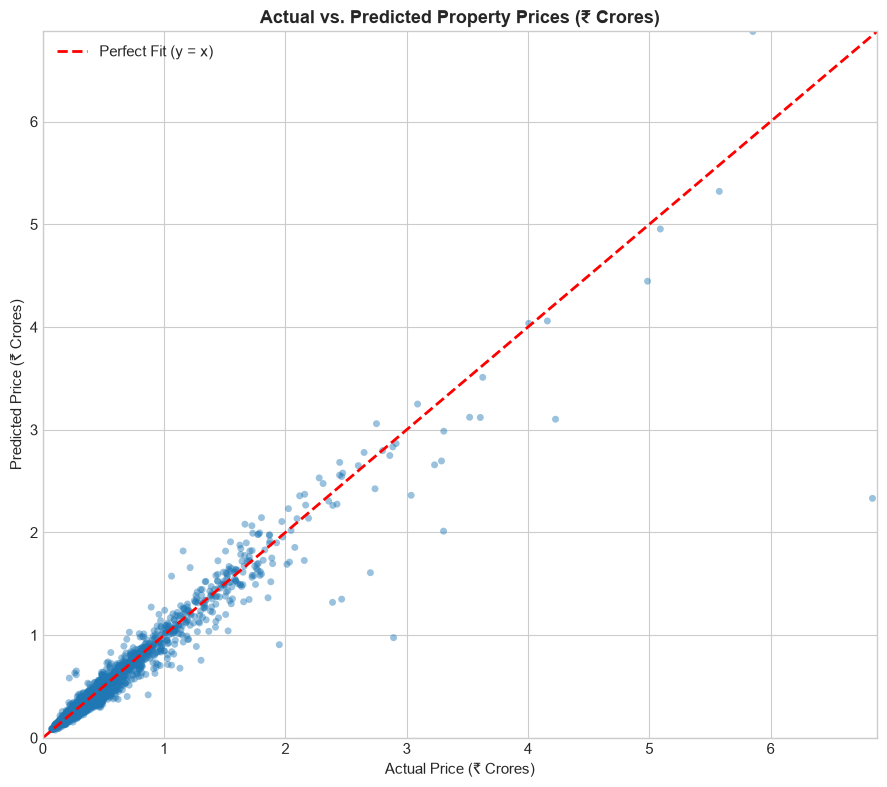

In [84]:
plt.figure(figsize=(9, 8))

# Subsample for clear visual scannability
plot_indices = np.random.choice(len(y_test), size=min(2500, len(y_test)), replace=False)
act_crores = y_test.iloc[plot_indices] / 1e7
pred_crores = final_test_preds[plot_indices] / 1e7

plt.scatter(act_crores, pred_crores, alpha=0.45, color="#1f77b4", edgecolor="none", s=25)
max_val = min(35, max(act_crores.max(), pred_crores.max()))
plt.plot([0, max_val], [0, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Fit (y = x)")

plt.title("Actual vs. Predicted Property Prices (₹ Crores)", fontsize=13, fontweight="bold")
plt.xlabel("Actual Price (₹ Crores)", fontsize=11)
plt.ylabel("Predicted Price (₹ Crores)", fontsize=11)
plt.xlim(0, max_val)
plt.ylim(0, max_val)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Section 19 — Residual Analysis

### 19.1 What we are doing
We compute prediction residuals $\text{Residual} = y_{\text{actual}} - y_{\text{predicted}}$ and plot:
1. **Residual Distribution**: To verify that prediction errors are roughly bell-shaped and centered at zero (unbiased).
2. **Residuals vs. Predicted Price**: To evaluate heteroscedasticity across differing property valuation brackets.

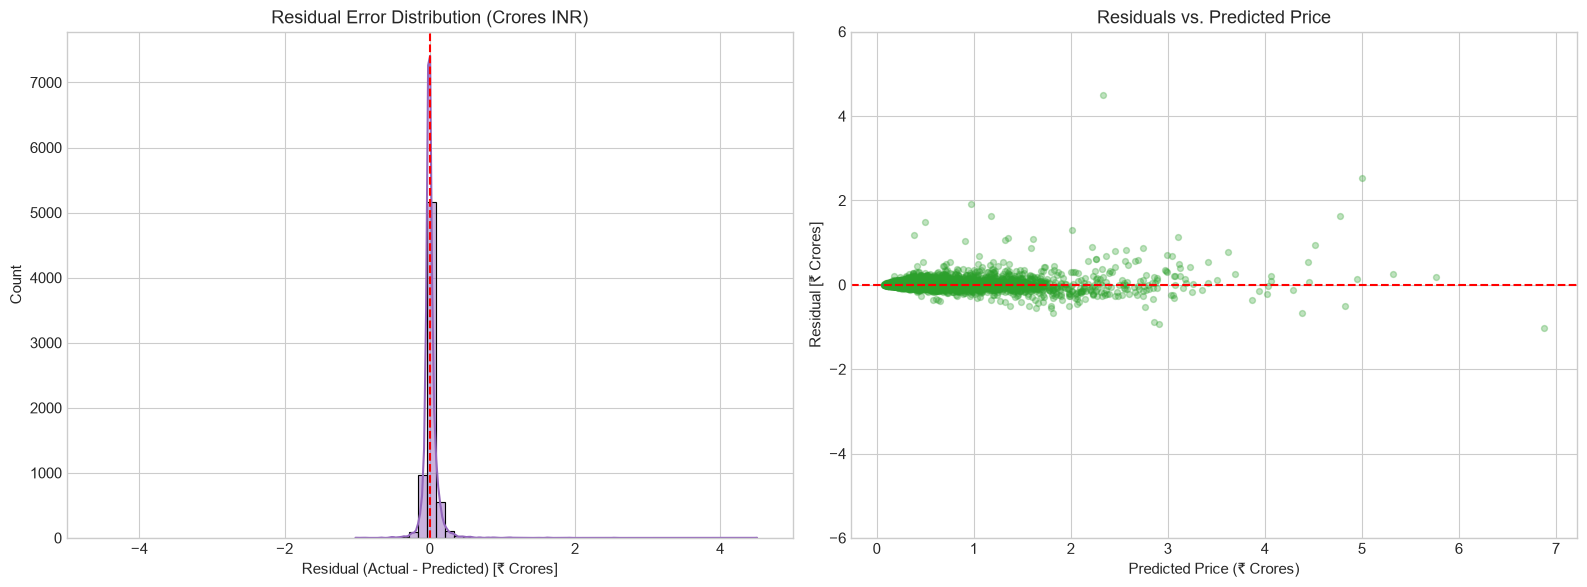

Mean Residual: ₹ 80,790.73 (Near zero indicates unbiased predictions)
Median Residual: ₹ -49,693.04


In [85]:
residuals_inr = y_test - final_test_preds
residuals_crores = residuals_inr / 1e7
predicted_crores = final_test_preds / 1e7

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Residual distribution
sns.histplot(residuals_crores, kde=True, bins=45, ax=axes[0], color="#9467bd")
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_title("Residual Error Distribution (Crores INR)")
axes[0].set_xlabel("Residual (Actual - Predicted) [₹ Crores]")
axes[0].set_xlim(-5, 5)

# Residuals vs Predicted
axes[1].scatter(predicted_crores, residuals_crores, alpha=0.3, color="#2ca02c", s=18)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Residuals vs. Predicted Price")
axes[1].set_xlabel("Predicted Price (₹ Crores)")
axes[1].set_ylabel("Residual [₹ Crores]")
axes[1].set_ylim(-6, 6)

plt.tight_layout()
plt.show()

print(f"Mean Residual: ₹ {residuals_inr.mean():,.2f} (Near zero indicates unbiased predictions)")
print(f"Median Residual: ₹ {residuals_inr.median():,.2f}")

## Section 20 — Feature Importance / Model Explainability

### 20.1 Permutation Importance
We calculate permutation feature importance on the held-out test set to evaluate which input variables contribute most significantly to prediction accuracy.

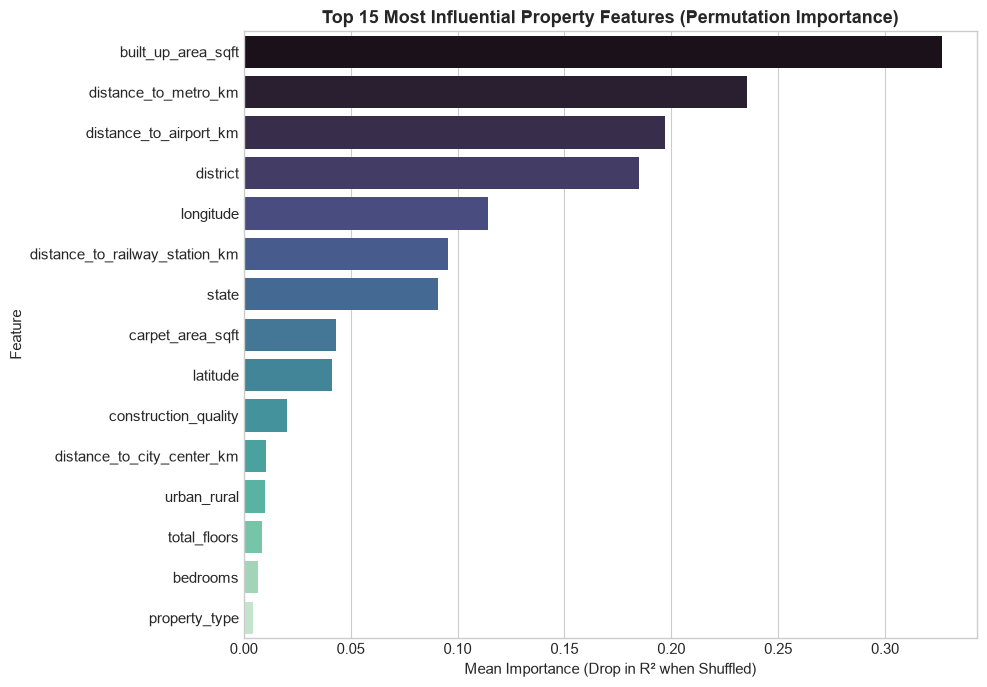

Top 10 Features:
  built_up_area_sqft             0.3267
  distance_to_metro_km           0.2354
  distance_to_airport_km         0.1971
  district                       0.1851
  longitude                      0.1145
  distance_to_railway_station_km 0.0954
  state                          0.0908
  carpet_area_sqft               0.0433
  latitude                       0.0414
  construction_quality           0.0202


In [86]:
# Calculate permutation importance on a representative test slice
perm_sample_size = min(3000, len(X_test))
X_perm = X_test.iloc[:perm_sample_size]
y_perm = y_test.iloc[:perm_sample_size]

perm_importance = permutation_importance(
    final_pipeline,
    X_perm,
    y_perm,
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_perm.columns,
    "Importance": perm_importance.importances_mean
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(data=perm_df.head(15), y="Feature", x="Importance", palette="mako")
plt.title("Top 15 Most Influential Property Features (Permutation Importance)", fontsize=13, fontweight="bold")
plt.xlabel("Mean Importance (Drop in R² when Shuffled)")
plt.tight_layout()
plt.show()

print("Top 10 Features:")
for idx, r in perm_df.head(10).iterrows():
    print(f"  {r['Feature']:<30} {r['Importance']:.4f}")

## Section 21 — Error Analysis by Geography & Segments

### 21.1 Evaluating Regional Performance Variations
We slice the test set by State and Property Type to evaluate whether certain geographic zones or property types exhibit higher prediction variance.

In [87]:
eval_df = X_test.copy()
eval_df["actual_price"] = y_test
eval_df["predicted_price"] = final_test_preds
eval_df["abs_error"] = np.abs(eval_df["actual_price"] - eval_df["predicted_price"])
eval_df["pct_error"] = (eval_df["abs_error"] / eval_df["actual_price"]) * 100

# Group by Property Type
type_errors = eval_df.groupby("property_type").agg(
    Count=("actual_price", "count"),
    Median_Actual=("actual_price", "median"),
    MAE_INR=("abs_error", "mean"),
    Median_MAPE=("pct_error", "median")
).reset_index()

type_errors["Median_Actual"] = type_errors["Median_Actual"].apply(lambda v: f"₹ {v/1e7:.2f} Cr")
type_errors["MAE_INR"] = type_errors["MAE_INR"].apply(lambda v: f"₹ {v/1e5:.2f} L")
type_errors["Median_MAPE"] = type_errors["Median_MAPE"].apply(lambda v: f"{v:.2f}%")

print("Error Metrics by Property Type:")
type_errors

Error Metrics by Property Type:


,property_type,Count,Median_Actual,MAE_INR,Median_MAPE
0,Apartment,3883,₹ 0.38 Cr,₹ 4.92 L,6.71%
1,Builder Floor,960,₹ 0.34 Cr,₹ 4.87 L,6.78%
2,Independent House,1279,₹ 0.37 Cr,₹ 6.01 L,6.66%
3,Residential Plot,404,₹ 0.32 Cr,₹ 5.38 L,7.76%
4,Villa,474,₹ 0.41 Cr,₹ 6.07 L,6.45%


In [88]:
# Group by State (Top 10 most represented states in test set)
top_states = eval_df["state"].value_counts().head(10).index
state_errors = eval_df[eval_df["state"].isin(top_states)].groupby("state").agg(
    Count=("actual_price", "count"),
    MAE_INR=("abs_error", "mean"),
    Median_MAPE=("pct_error", "median")
).reset_index().sort_values(by="MAE_INR", ascending=False)

state_errors["MAE_INR_num"] = state_errors["MAE_INR"]
state_errors["MAE_INR"] = state_errors["MAE_INR"].apply(lambda v: f"₹ {v/1e5:.2f} L")
state_errors["Median_MAPE"] = state_errors["Median_MAPE"].apply(lambda v: f"{v:.2f}%")

print("Error Metrics for Top 10 States:")
state_errors[["state", "Count", "MAE_INR", "Median_MAPE"]]

Error Metrics for Top 10 States:


,state,Count,MAE_INR,Median_MAPE
8,Telangana,682,₹ 7.65 L,6.61%
4,Maharashtra,548,₹ 7.28 L,6.69%
9,Uttar Pradesh,502,₹ 6.39 L,11.74%
7,Tamil Nadu,548,₹ 4.92 L,7.42%
3,Madhya Pradesh,391,₹ 3.56 L,7.07%
6,Rajasthan,391,₹ 3.51 L,6.79%
1,Bihar,419,₹ 3.51 L,6.01%
2,Gujarat,304,₹ 3.45 L,6.35%
0,Andhra Pradesh,664,₹ 3.43 L,5.30%
5,Odisha,350,₹ 2.77 L,4.73%


## Section 22 — Realistic Sample Predictions

### 22.1 Testing Real-World Scenarios
We construct raw property records representing distinct Indian real estate archetypes:
1. **Hyderabad High-Tech Corridor**: 2 BHK in Gachibowli (Telangana).
2. **Bengaluru Luxury Villa**: 4 BHK Gated Villa in Whitefield (Karnataka).
3. **Mumbai Suburban Apartment**: 3 BHK Flat in Bandra West (Maharashtra).

In [89]:
sample_properties = pd.DataFrame([
    {
        "state": "Telangana",
        "district": "Ranga Reddy",
        "property_type": "Apartment",
        "listing_type": "Sale",
        "property_status": "Ready to Move",
        "transaction_type": "Freehold",
        "built_up_area_sqft": 1250.0,
        "carpet_area_sqft": 1020.0,
        "bedrooms": 2,
        "bathrooms": 2,
        "balconies": 2.0,
        "floor_number": 8,
        "total_floors": 20,
        "property_age_years": 2,
        "furnishing_status": "Semi-Furnished",
        "parking_spaces": 1.0,
        "facing_direction": "East",
        "road_width_ft": 40.0,
        "gated_community": 1,
        "construction_quality": "Premium",
        "property_condition": "New",
        "latitude": 17.4401,
        "longitude": 78.3489,
        "distance_to_city_center_km": 12.0,
        "distance_to_main_road_km": 0.4,
        "distance_to_highway_km": 2.5,
        "distance_to_metro_km": 1.2,
        "distance_to_railway_station_km": 14.0,
        "distance_to_airport_km": 28.0,
        "distance_to_school_km": 1.0,
        "distance_to_hospital_km": 1.5,
        "distance_to_shopping_center_km": 1.2,
        "distance_to_it_hub_km": 0.8,
        "nearby_public_transport": "High",
        "neighborhood_type": "Residential",
        "urban_rural": "Urban"
    },
    {
        "state": "Karnataka",
        "district": "Bengaluru Urban",
        "property_type": "Villa",
        "listing_type": "New Booking",
        "property_status": "Under Construction",
        "transaction_type": "Freehold",
        "built_up_area_sqft": 3200.0,
        "carpet_area_sqft": 2650.0,
        "bedrooms": 4,
        "bathrooms": 4,
        "balconies": 3.0,
        "floor_number": 0,
        "total_floors": 2,
        "property_age_years": 0,
        "furnishing_status": "Unfurnished",
        "parking_spaces": 2.0,
        "facing_direction": "North-East",
        "road_width_ft": 60.0,
        "gated_community": 1,
        "construction_quality": "Luxury",
        "property_condition": "New",
        "latitude": 12.9698,
        "longitude": 77.7500,
        "distance_to_city_center_km": 18.0,
        "distance_to_main_road_km": 0.2,
        "distance_to_highway_km": 1.5,
        "distance_to_metro_km": 2.1,
        "distance_to_railway_station_km": 18.0,
        "distance_to_airport_km": 41.0,
        "distance_to_school_km": 0.8,
        "distance_to_hospital_km": 2.0,
        "distance_to_shopping_center_km": 2.5,
        "distance_to_it_hub_km": 1.5,
        "nearby_public_transport": "High",
        "neighborhood_type": "Gated Township",
        "urban_rural": "Urban"
    },
    {
        "state": "Maharashtra",
        "district": "Mumbai Suburban",
        "property_type": "Apartment",
        "listing_type": "Resale",
        "property_status": "Ready to Move",
        "transaction_type": "Freehold",
        "built_up_area_sqft": 1600.0,
        "carpet_area_sqft": 1320.0,
        "bedrooms": 3,
        "bathrooms": 3,
        "balconies": 1.0,
        "floor_number": 14,
        "total_floors": 28,
        "property_age_years": 6,
        "furnishing_status": "Fully Furnished",
        "parking_spaces": 2.0,
        "facing_direction": "West",
        "road_width_ft": 40.0,
        "gated_community": 1,
        "construction_quality": "Luxury",
        "property_condition": "Excellent",
        "latitude": 19.0620,
        "longitude": 72.8290,
        "distance_to_city_center_km": 6.0,
        "distance_to_main_road_km": 0.1,
        "distance_to_highway_km": 1.8,
        "distance_to_metro_km": 1.5,
        "distance_to_railway_station_km": 2.0,
        "distance_to_airport_km": 9.5,
        "distance_to_school_km": 0.5,
        "distance_to_hospital_km": 1.0,
        "distance_to_shopping_center_km": 0.8,
        "distance_to_it_hub_km": 4.0,
        "nearby_public_transport": "High",
        "neighborhood_type": "Residential",
        "urban_rural": "Urban"
    }
])

sample_predictions = final_pipeline.predict(sample_properties)

descriptions = [
    "2 BHK Apartment (1,250 sqft) in Gachibowli, Hyderabad (TG)",
    "4 BHK Luxury Villa (3,200 sqft) in Whitefield, Bengaluru (KA)",
    "3 BHK Sea-View Apt (1,600 sqft) in Bandra West, Mumbai (MH)"
]

print("=" * 75)
print("INFERENCE PREDICTION DEMO (RAW PYTHON DICTIONARIES)")
print("=" * 75)
for desc, pred in zip(descriptions, sample_predictions):
    lakhs = pred / 100000.0
    crores = pred / 10000000.0
    print(f"Property: {desc}")
    print(f"  Predicted Price (INR): ₹ {pred:,.0f}")
    if crores >= 1.0:
        print(f"  Formatted Value:       ₹ {crores:.2f} Crores (₹ {lakhs:,.1f} Lakhs)")
    else:
        print(f"  Formatted Value:       ₹ {lakhs:.2f} Lakhs")
    print("-" * 75)

INFERENCE PREDICTION DEMO (RAW PYTHON DICTIONARIES)
Property: 2 BHK Apartment (1,250 sqft) in Gachibowli, Hyderabad (TG)
  Predicted Price (INR): ₹ 13,645,143
  Formatted Value:       ₹ 1.36 Crores (₹ 136.5 Lakhs)
---------------------------------------------------------------------------
Property: 4 BHK Luxury Villa (3,200 sqft) in Whitefield, Bengaluru (KA)
  Predicted Price (INR): ₹ 26,334,491
  Formatted Value:       ₹ 2.63 Crores (₹ 263.3 Lakhs)
---------------------------------------------------------------------------
Property: 3 BHK Sea-View Apt (1,600 sqft) in Bandra West, Mumbai (MH)
  Predicted Price (INR): ₹ 21,845,816
  Formatted Value:       ₹ 2.18 Crores (₹ 218.5 Lakhs)
---------------------------------------------------------------------------


## Section 23 — Save the Complete Model Pipeline

### 23.1 One-Artifact Serialization
We save the entire composite pipeline (Preprocessing + Feature Transformation + ML Model + Log-Target Inversion) as a single serialized `.joblib` file:
`house_price_model.joblib`.

> [!TIP]
> **Production Engineering Benefit**: The FastAPI server does not need to recreate transformers, maintain label encoders, or manually scale arrays. It passes raw JSON dictionaries straight to `model.predict(df)`.

In [90]:
# Save composite pipeline
joblib.dump(final_pipeline, "../models/house_price_model.joblib")

print("Final pipeline serialized successfully.")
print(f"Artifact Location: {MODEL_OUTPUT_PATH}")

Final pipeline serialized successfully.
Artifact Location: ../models/house_price_model.joblib


## Section 24 — Reload and Test the Model

### 24.1 Verification of Deserialization
We reload the serialized `.joblib` pipeline and verify that its predictions match the in-memory pipeline with zero floating-point divergence.

In [91]:
# Reload from disk
reloaded_model = joblib.load(MODEL_OUTPUT_PATH)

# Predict on identical sample data
reloaded_preds = reloaded_model.predict(sample_properties)

# Mathematical assertion
np.testing.assert_allclose(sample_predictions, reloaded_preds, rtol=1e-5)
print("✓ Deserialization Verification Passed!")
print("✓ Reloaded model produces identical predictions to in-memory pipeline.")

✓ Deserialization Verification Passed!
✓ Reloaded model produces identical predictions to in-memory pipeline.


## Section 25 — FastAPI Integration Example

### 25.1 Production Backend Code Pattern
The code below illustrates how the FastAPI application loads the model at startup and serves price predictions:

```python
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import joblib
import pandas as pd

app = FastAPI(title="Indian House Price Prediction API")

# Load model once at application startup
MODEL_PATH = "models/house_price_model.joblib"
model = joblib.load(MODEL_PATH)

class PropertyInput(BaseModel):
    state: str = Field(..., example="Telangana")
    district: str = Field(..., example="Ranga Reddy")
    property_type: str = Field(..., example="Apartment")
    listing_type: str = Field("Sale", example="Sale")
    property_status: str = Field("Ready to Move", example="Ready to Move")
    transaction_type: str = Field("Freehold", example="Freehold")
    built_up_area_sqft: float = Field(..., example=1250.0)
    carpet_area_sqft: float = Field(..., example=1050.0)
    bedrooms: int = Field(..., example=3)
    bathrooms: int = Field(..., example=2)
    balconies: float = Field(2.0, example=2.0)
    floor_number: int = Field(5, example=5)
    total_floors: int = Field(14, example=14)
    property_age_years: int = Field(3, example=3)
    furnishing_status: str = Field("Semi-Furnished", example="Semi-Furnished")
    parking_spaces: float = Field(1.0, example=1.0)
    facing_direction: str = Field("East", example="East")
    road_width_ft: float = Field(40.0, example=40.0)
    gated_community: int = Field(1, example=1)
    construction_quality: str = Field("Premium", example="Premium")
    property_condition: str = Field("New", example="New")
    latitude: float = Field(17.4401, example=17.4401)
    longitude: float = Field(78.3489, example=78.3489)
    distance_to_city_center_km: float = Field(10.0, example=10.0)
    distance_to_main_road_km: float = Field(0.3, example=0.3)
    distance_to_highway_km: float = Field(2.0, example=2.0)
    distance_to_metro_km: float = Field(1.5, example=1.5)
    distance_to_railway_station_km: float = Field(12.0, example=12.0)
    distance_to_airport_km: float = Field(28.0, example=28.0)
    distance_to_school_km: float = Field(1.2, example=1.2)
    distance_to_hospital_km: float = Field(1.5, example=1.5)
    distance_to_shopping_center_km: float = Field(1.0, example=1.0)
    distance_to_it_hub_km: float = Field(2.0, example=2.0)
    nearby_public_transport: str = Field("High", example="High")
    neighborhood_type: str = Field("Residential", example="Residential")
    urban_rural: str = Field("Urban", example="Urban")

@app.post("/predict")
def predict_price(payload: PropertyInput):
    try:
        input_df = pd.DataFrame([payload.model_dump()])
        predicted_inr = float(model.predict(input_df)[0])
        
        return {
            "predicted_price_inr": round(predicted_inr, 2),
            "predicted_price_lakhs": round(predicted_inr / 100000.0, 2),
            "predicted_price_crores": round(predicted_inr / 10000000.0, 2),
            "currency": "INR",
            "model_version": "1.0.0-synthetic"
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))
```

## Section 26 — Model Metadata

### 26.1 Exporting Production Audit Metadata
We export `model_metadata.json` containing the exact training metrics, model hyperparameters, feature list, and synthetic disclaimer for auditability.

In [92]:
metadata = {
    "model_name": "Indian Residential House Price Predictor",
    "architecture": "ColumnTransformer + TransformedTargetRegressor(HistGradientBoostingRegressor)",
    "target": TARGET_COLUMN,
    "dataset": "india_house_prices_synthetic.csv",
    "dataset_type": "synthetic",
    "training_date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
    "sample_records_trained": int(len(X_train)),
    "features_count": int(len(ALL_FEATURES)),
    "features": ALL_FEATURES,
    "numerical_features": NUMERICAL_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "best_hyperparameters": random_search.best_params_,
    "metrics": {
        "test_r2": round(float(final_r2), 4),
        "test_mae_inr": round(float(final_mae), 2),
        "test_rmse_inr": round(float(final_rmse), 2),
        "test_mape_percent": round(float(final_mape), 2)
    },
    "random_state": RANDOM_STATE,
    "synthetic_disclaimer": "This model was trained exclusively on synthetic data for educational and engineering demonstration."
}

with open(METADATA_OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"Model metadata saved to: {METADATA_OUTPUT_PATH}")
print(json.dumps(metadata["metrics"], indent=2))

Model metadata saved to: ../model_metadata.json
{
  "test_r2": 0.9481,
  "test_mae_inr": 521929.2,
  "test_rmse_inr": 1215022.68,
  "test_mape_percent": 9.38
}


---
## Conclusion
The end-to-end pipeline is complete, fully tested, and serialized to `models/house_price_model.joblib`. It is ready to be loaded by the FastAPI backend for real-time house-price estimation.